# Tier 1 - Pitch estimation from a simulated IMU

Gyro integration vs accelerometer tilt vs complementary filter (tau = 0.2 s). Units in code are rad, rad/s, m/s^2; degrees appear only in printed tables and plots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

import imu_sim
import imu_filters
import imu_metrics
import imu_plots

TAU = 0.2

def run_estimators(sim):
    # Only measured data (t, gyro, accel) is passed to the filters; no *_true fields.
    accel_pitch = imu_filters.accel_tilt(sim.accel)[1]
    return {
        'gyro': imu_filters.gyro_integrate(sim.t, sim.gyro[:, 1], 0.0),
        'accel': accel_pitch,
        'complementary': imu_filters.complementary_filter(sim.t, sim.gyro[:, 1], accel_pitch, tau=TAU),
    }

## Standard run (S1: 60 s, 100 Hz, seed 0)

method           RMSE (deg)   max abs err (deg)
gyro                 19.684              34.506
accel                 0.292               1.057
complementary         0.140               0.347


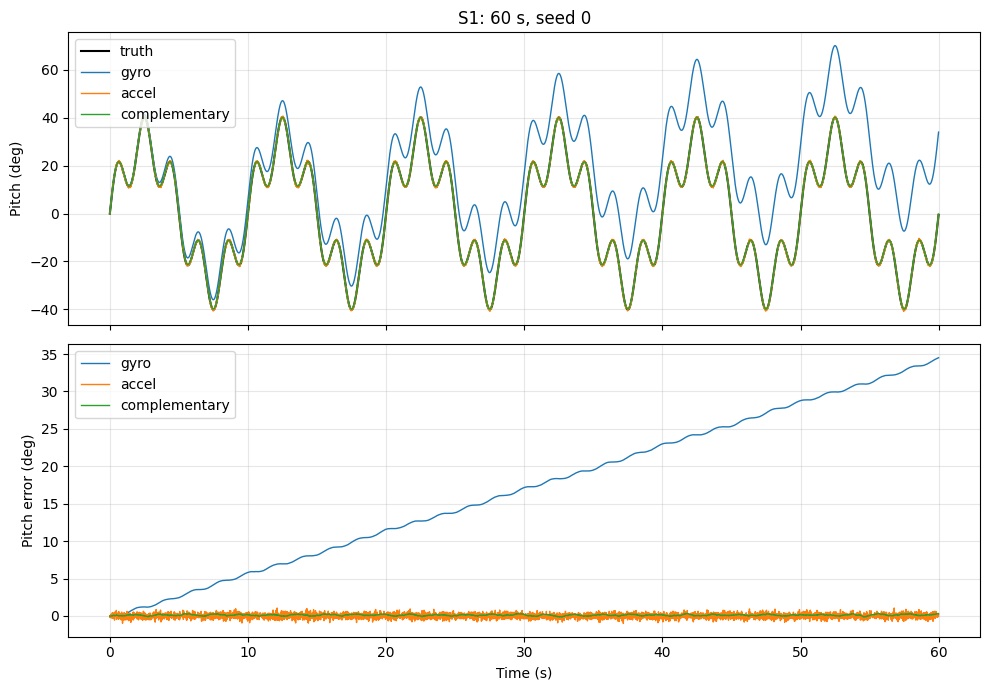

In [2]:
sim1 = imu_sim.simulate_pitch_imu(seed=0)
est1 = run_estimators(sim1)

print(f"{'method':<15}{'RMSE (deg)':>12}{'max abs err (deg)':>20}")
for name, est in est1.items():
    r = np.rad2deg(imu_metrics.rmse(est, sim1.pitch_true))
    m = np.rad2deg(imu_metrics.max_abs_error(est, sim1.pitch_true))
    print(f'{name:<15}{r:>12.3f}{m:>20.3f}')

fig1 = imu_plots.plot_comparison(sim1.t, sim1.pitch_true, est1, title='S1: 60 s, seed 0')
display(fig1)
plt.close(fig1)

## Long run (S2: 600 s, 100 Hz, seed 0)

method           drift rate (deg/s)
gyro                       0.572435
accel                      0.000009
complementary              0.000010


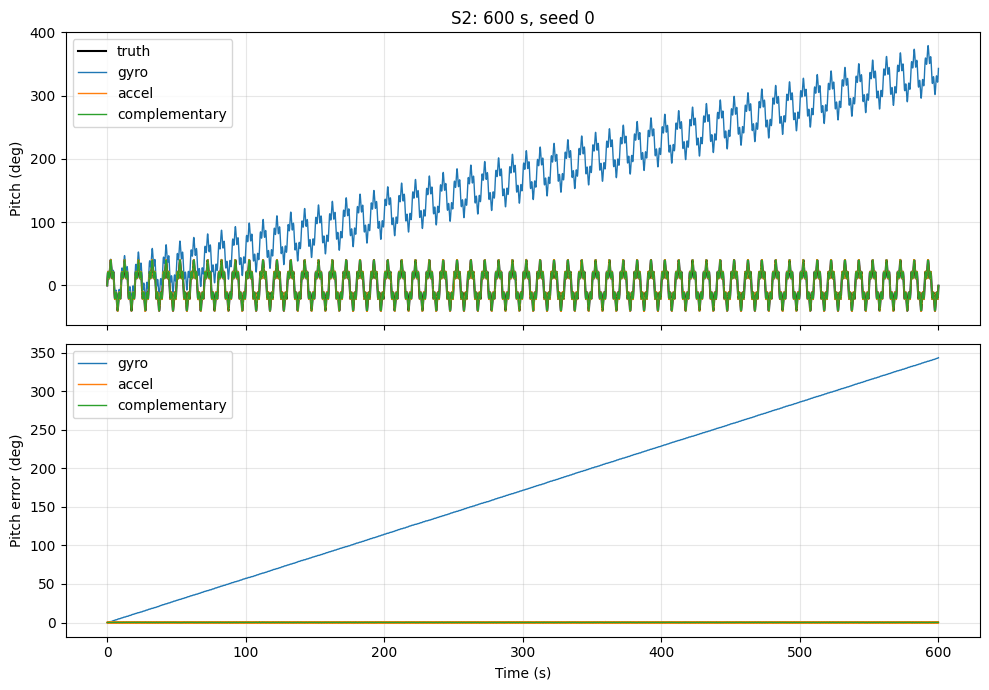

In [3]:
sim2 = imu_sim.simulate_pitch_imu(duration=600.0, seed=0)
est2 = run_estimators(sim2)

print(f"{'method':<15}{'drift rate (deg/s)':>20}")
for name, est in est2.items():
    d = np.rad2deg(imu_metrics.drift_rate(sim2.t, est, sim2.pitch_true))
    print(f'{name:<15}{d:>20.6f}')

fig2 = imu_plots.plot_comparison(sim2.t, sim2.pitch_true, est2, title='S2: 600 s, seed 0')
display(fig2)
plt.close(fig2)

## Discussion

- **Gyro integration** tracks the motion shape but integrates the constant 0.01 rad/s bias, so its error grows linearly at about 0.57 deg/s (about 34 deg after 60 s, about 340 deg after 600 s). Its RMSE is dominated by that drift.
- **Accelerometer tilt** is unbiased and does not drift, but each sample carries white noise of roughly 0.05/9.81 rad (about 0.3 deg), so its error is noisy yet bounded.
- **Complementary filter** (tau = 0.2 s) trusts the gyro at high frequency and the accelerometer at low frequency. The gyro bias leaves only a small constant offset of about b*tau (0.002 rad, about 0.11 deg) and the accelerometer noise is low-passed, so its RMSE is below that of the accelerometer alone and its drift rate is essentially zero.
- The residual CF error is a trade-off set by tau: a larger tau smooths more but increases the bias offset and lag.